# A4 · E2 — Does the churn model beat simple rules? (real data)

Calibrated mean(LR, LightGBM) ensemble. SMOTE-NC vs class weights is compared inside CV folds;
calibration (Platt) uses a held-out slice of the training split; the test split is untouched
until evaluation. Baselines: a visit-threshold rule and a single logistic regression.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anchorai.config import get_settings
from anchorai.features import build_features
from anchorai.scenario.tables import read_tables

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = get_settings().anchorai_seed
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

tables = read_tables()
members = tables["members"]
labels = members.set_index("member_id")
features = build_features(members)
is_train = labels["split"] == "train"
print(len(members), "members;", is_train.sum(), "train /", (~is_train).sum(), "test")

4000 members; 3200 train / 800 test


In [2]:
from anchorai.discovery import churn

result = churn.train(features, labels["churn"], labels["split"], SEED)
card = result.card
metrics = ["f1", "precision", "recall", "pr_auc", "roc_auc", "brier"]
comparison = pd.DataFrame({
    "AnchorAI ensemble (calibrated)": card["test"],
    "single LR": card["baselines"]["single_lr"],
    card["baselines"]["visit_rule"]["rule"]: card["baselines"]["visit_rule"],
}).T[metrics].astype(float).round(3)
comparison.to_csv(RES / "e2_model_vs_baselines.csv")
comparison

,f1,precision,recall,pr_auc,roc_auc,brier
AnchorAI ensemble (calibrated),0.908,0.906,0.910,0.973,0.988,0.035
single LR,0.862,0.818,0.910,0.953,0.978,0.056
churn if visits per week this month <= 1.63,0.549,0.426,0.774,0.390,0.699,0.336


In [3]:
resampling = pd.DataFrame({r: card["resampling"][r] for r in churn.RESAMPLING}).T[["f1", "pr_auc", "brier"]].astype(float).round(4)
print("chosen:", card["resampling"]["chosen"])
resampling.to_csv(RES / "e2_resampling_cv.csv")
resampling

chosen: class_weight


,f1,pr_auc,brier
smote_nc,0.9052,0.9698,0.0386
class_weight,0.9060,0.9723,0.0393


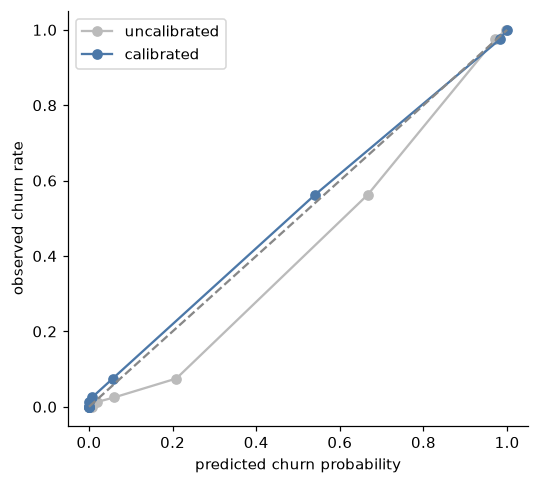

In [4]:
test = ~is_train
y, p = labels.loc[test, "churn"].to_numpy(), result.probabilities[test].to_numpy()
raw = result.model.raw_proba(features[test])

from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(5, 4.5))
for probs, name, colour in ((raw, "uncalibrated", "#bbbbbb"), (p, "calibrated", "#4c78a8")):
    obs, pred = calibration_curve(y, probs, n_bins=10, strategy="quantile")
    ax.plot(pred, obs, marker="o", label=name, color=colour)
ax.plot([0, 1], [0, 1], ls="--", color="#888")
ax.set_xlabel("predicted churn probability"); ax.set_ylabel("observed churn rate"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "e2_calibration.png"); plt.show()

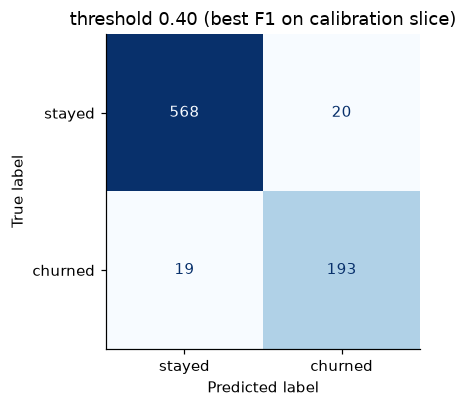

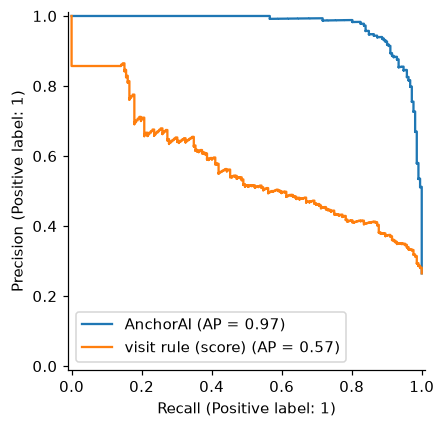

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(4.2, 3.8))
ConfusionMatrixDisplay.from_predictions(y, p >= result.model.threshold, display_labels=["stayed", "churned"], ax=ax, colorbar=False, cmap="Blues")
ax.set_title(f"threshold {result.model.threshold:.2f} (best F1 on calibration slice)")
fig.tight_layout(); fig.savefig(FIG / "e2_confusion.png"); plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
PrecisionRecallDisplay.from_predictions(y, p, ax=ax, name="AnchorAI")
rule = (-features.loc[test, "avg_class_frequency_current_month"]).to_numpy()
PrecisionRecallDisplay.from_predictions(y, rule, ax=ax, name="visit rule (score)")
fig.tight_layout(); fig.savefig(FIG / "e2_pr_curve.png"); plt.show()

## Drivers (SHAP)
Per-member drivers in the app are the mean of LR log-odds terms and LightGBM SHAP values.
The global view below is the LightGBM component's SHAP summary on the test split.

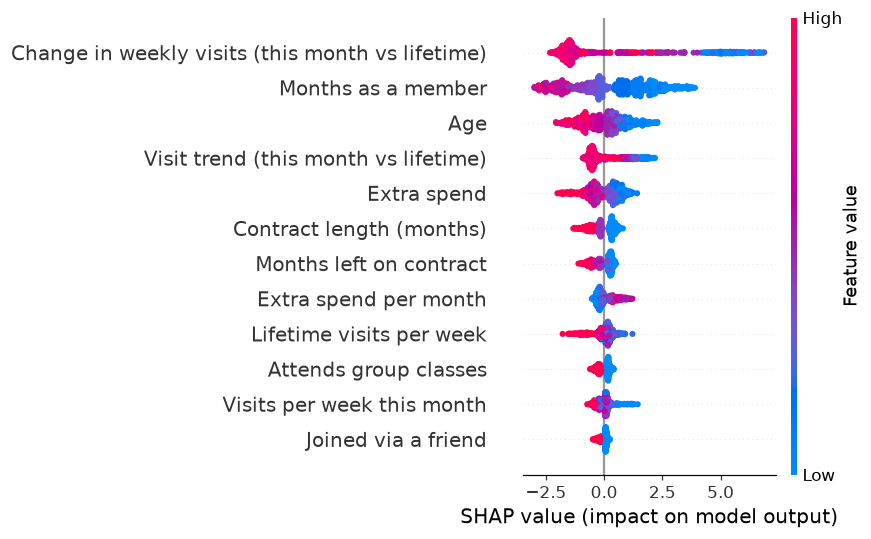

In [6]:
import shap
from anchorai.features import LABELS

booster = result.model.lgbm[-1]
x_test = features.loc[test, result.model.columns]
values = shap.TreeExplainer(booster).shap_values(x_test.to_numpy())
values = values[1] if isinstance(values, list) else values
shap.summary_plot(values, x_test.rename(columns=LABELS), show=False, max_display=12, plot_size=(8, 5))
plt.tight_layout(); plt.savefig(FIG / "e2_shap.png"); plt.show()

## Leakage and fairness

In [7]:
leak = pd.DataFrame({k: v["test"] for k, v in card["leakage"].items()}).T[metrics].astype(float).round(3)
leak.to_csv(RES / "e2_leakage_test.csv")
leak

,f1,precision,recall,pr_auc,roc_auc,brier
with_suspect,0.908,0.906,0.910,0.973,0.988,0.035
without_suspect,0.817,0.768,0.873,0.900,0.957,0.069


In [8]:
rows = []
for attribute, f in card["fairness"].items():
    for group, r in f["groups"].items():
        rows.append({"attribute": attribute, "group": group, **r})
fairness = pd.DataFrame(rows).round(3)
fairness.to_csv(RES / "e2_fairness.csv", index=False)
print({a: {"recall_gap": round(f["recall_gap"], 3), "fpr_gap": round(f["fpr_gap"], 3)} for a, f in card["fairness"].items()})
fairness

{'age_band': {'recall_gap': 0.463, 'fpr_gap': 0.139}, 'gender': {'recall_gap': 0.094, 'fpr_gap': 0.022}}


,attribute,group,n,churn_rate,recall,precision,fpr
0,age_band,18-25,108,0.611,0.985,0.915,0.143
1,age_band,26-30,425,0.289,0.943,0.899,0.043
2,age_band,31+,267,0.086,0.522,0.923,0.004
3,gender,0,389,0.260,0.861,0.870,0.045
4,gender,1,411,0.270,0.955,0.938,0.023


In [9]:
older = fairness[(fairness.attribute == "age_band") & (fairness.group == "31+")].iloc[0]
print(f"31+ members: {older.n} in test, churn rate {older.churn_rate:.1%}, recall {older.recall:.2f}")
print("Mitigation for staff use: a lower review threshold for this band, or treat their medium-risk members as at-risk.")

31+ members: 267 in test, churn rate 8.6%, recall 0.52
Mitigation for staff use: a lower review threshold for this band, or treat their medium-risk members as at-risk.


## Why are the probabilities so bimodal? (HANDOFFS #2)

Every training member's served score is **out-of-fold**: it comes from a model fitted on the other
four folds, so no score has seen its own label. Test members are scored by the final model. Below,
the served scores are compared with what in-sample scoring would give and with the model that drops
the leakage-suspect columns.

In [10]:
from anchorai.discovery.churn import FEATURES, SUSPECT, fit, score_distribution

served = result.probabilities
y_all = labels["churn"]
in_sample = pd.Series(result.model.predict_proba(features[is_train]), index=features.index[is_train])
safe = [c for c in FEATURES if c not in SUSPECT]
no_suspect = fit(features[is_train], y_all[is_train], card["resampling"]["chosen"], safe, SEED)
rows = {
    "train, out-of-fold (served)": score_distribution(served[is_train], y_all[is_train]),
    "train, in-sample (not served)": score_distribution(in_sample, y_all[is_train]),
    "test (served)": score_distribution(served[~is_train], y_all[~is_train]),
    "test, without suspect columns": score_distribution(
        pd.Series(no_suspect.predict_proba(features[~is_train]), index=features.index[~is_train]),
        y_all[~is_train],
    ),
}
distribution = pd.DataFrame(rows).T
distribution.to_csv(RES / "e2_score_distribution.csv")
distribution.round(3)

,n,median,low_share,medium_share,high_share,between_5_and_95,error_at_half
"train, out-of-fold (served)",3200.0,0.009,0.713,0.045,0.242,0.222,0.049
"train, in-sample (not served)",3200.0,0.003,0.720,0.032,0.248,0.176,0.028
test (served),800.0,0.002,0.724,0.030,0.246,0.151,0.046
"test, without suspect columns",800.0,0.023,0.699,0.070,0.231,0.365,0.099


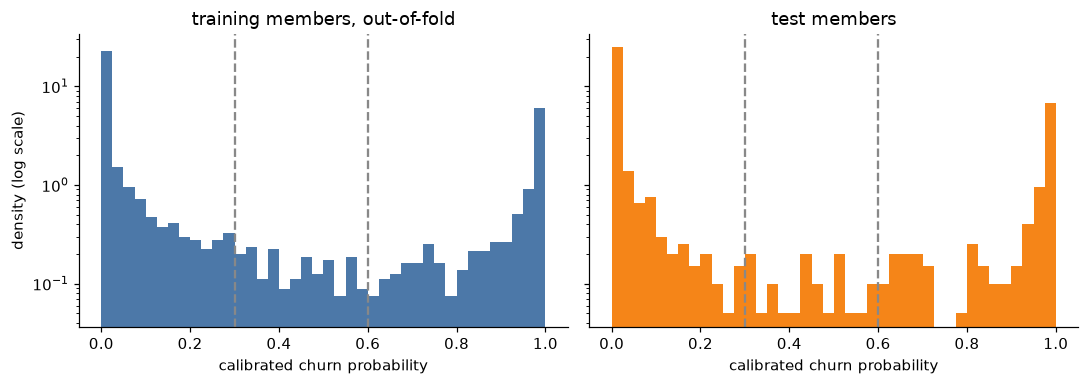

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
bins = np.linspace(0, 1, 41)
for ax, (name, values, colour) in zip(axes, [
    ("training members, out-of-fold", served[is_train], "#4c78a8"),
    ("test members", served[~is_train], "#f58518"),
]):
    ax.hist(values, bins=bins, color=colour, density=True)
    ax.axvline(0.3, ls="--", color="#888"); ax.axvline(0.6, ls="--", color="#888")
    ax.set_yscale("log"); ax.set_title(name); ax.set_xlabel("calibrated churn probability")
axes[0].set_ylabel("density (log scale)")
fig.tight_layout(); fig.savefig(FIG / "e2_score_distribution.png"); plt.show()

**Is it calibrated where it matters?** Observed churn rate per risk band on the test split. If the
extremes were overconfident, low-band members would churn far more than their predicted rate.

In [12]:
bands = pd.cut(served[~is_train], [-0.1, 0.3, 0.6, 1.1], labels=["low", "medium", "high"], right=False)
by_band = pd.DataFrame({"p": served[~is_train], "churned": y_all[~is_train], "band": bands}).groupby(
    "band", observed=True).agg(members=("p", "size"), mean_predicted=("p", "mean"), observed_rate=("churned", "mean"))
by_band.round(3).to_csv(RES / "e2_reliability_by_band.csv")
by_band.round(3)

,members,mean_predicted,observed_rate
band,,,
low,579,0.016,0.029
medium,24,0.441,0.417
high,197,0.951,0.939


**Options for rules that want a wider "watch" band.** Members per band on the served scores if
the medium cut-off moved down (the high cut-off stays at 0.6).

In [13]:
cutoffs = pd.DataFrame([
    {"medium_from": cut, "low": int((served < cut).sum()), "medium": int(((served >= cut) & (served < 0.6)).sum()),
     "high": int((served >= 0.6).sum())}
    for cut in (0.3, 0.2, 0.1, 0.05)
]).set_index("medium_from")
cutoffs.to_csv(RES / "e2_band_cutoffs.csv")
cutoffs

,low,medium,high
medium_from,,,
0.30,2861,169,970
0.20,2763,267,970
0.10,2620,410,970
0.05,2459,571,970


**Answer to #2.** The bimodality is a property of the data, not an artefact. The test split,
scored out-of-sample, is just as extreme, and each band churns at about its predicted rate. A few
Kaggle columns nearly decide the label (tenure, months left on the contract, this month's visits),
so a calibrated model is rightly sure about most members. Dropping the suspect columns makes scores
less extreme but less accurate. What *was* an artefact is that training members used to be scored
in-sample, which made them look easier to predict than they are; they are now out-of-fold, so their
error rate matches the test split.

**Reading.** The calibrated ensemble beats both baselines on F1 and PR-AUC, and calibration
brings predicted probabilities onto the observed rates, which the optimiser relies on. The
largest fairness gap is recall by age: churn among members aged 31+ is rare (about 9%) and the
model misses about half of it. This is reported, not hidden; see the mitigation above.